In [1]:
# imports
import sys, time, pickle as pkl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm
sys.path.append('../../code')
sys.path.append('../../code/butools2/Python')

import butools
butools.verbose = False
from butools.fitting import PHFromTrace, MAPFromTrace
from butools.map import MarginalMomentsFromMAP, LagkJointMomentsFromMAP, MarginalDistributionFromMAP
from butools.ph import SamplesFromPH
from butools.queues import MAPMAP1

<div dir="rtl">

# התאמת תהליכי הגעה מרקוביים (MAP) לנתונים

### בשיעור הקודם התאמנו התפלגות פאזה (PH) לנתונים. הנחנו בשקט הנחה חשובה: שהזמנים **בלתי תלויים** זה בזה.

### בהרבה מערכות אמיתיות זה לא נכון:

### - שיחות למוקד מגיעות בגלים: אחרי זמן בין הגעות קצר, בדרך כלל מגיע עוד זמן קצר.
### - בשעות עומס יש רצף של הגעות צפופות, ובשעות שקטות — רצף של הפסקות ארוכות.

### התפלגות PH מתארת רק את **צורת ההתפלגות** של זמן בודד. היא לא יודעת שום דבר על הקשר בין זמן אחד לזה שאחריו.

### היום נתאים **תהליך הגעה מרקובי** — Markovian Arrival Process, או בקיצור MAP — שמתאר גם את הצורה וגם את התלות.

</div>

<div dir="rtl">

## מהו MAP?

### MAP מוגדר על ידי שתי מטריצות בגודל $n \times n$:

### $D_0$ — קצבי מעברים בין שלבים **בלי** הגעה (על האלכסון: מינוס קצב היציאה הכולל מהשלב).
### $D_1$ — קצבי מעברים **עם** הגעה: כשהמעבר קורה, מגיע לקוח, והזמן הבא מתחיל בשלב החדש.

### לכן כל זמן בין הגעות הוא זמן ספיגה של התפלגות פאזה עם מטריצה $D_0$ — בדיוק כמו בשיעור הקודם.

### ההבדל: ב-PH כל זמן מתחיל מחדש לפי אותו וקטור $\alpha$. ב-MAP השלב שבו מתחיל הזמן הבא **תלוי בשלב שבו הסתיים הזמן הקודם**. כך נוצרת התלות.

### יש ל-MAP שני מרכיבים, ונבדוק את שניהם:

### 1. **ההתפלגות השולית** — התפלגות של זמן בודד. היא תמיד התפלגות פאזה (עם $D_0$, ועם וקטור התחלה שהוא ההתפלגות הסטציונרית של השלב ברגעי הגעה).
### 2. **התלות** — הקשר בין זמנים עוקבים.

### אם $D_1 = (-D_0\mathbf{1})\,\alpha$ — כלומר תמיד מתחילים מחדש לפי אותו $\alpha$ — ה-MAP הוא בעצם התפלגות PH עם זמנים בלתי תלויים.

</div>

<div dir="rtl">

## איך מודדים תלות? מקדמי אוטו-קורלציה

### נסמן ב-$X_t$ את הזמן ה-$t$ בין הגעות. מקדם אוטו-קורלציה בפיגור $L$, בחזקות $i$ ו-$j$:

$$ \rho_L(i,j) = \text{corr}\left(X_t^{\,i},\ X_{t+L}^{\,j}\right) $$

### בשיעור נשתמש בפיגורים $L=1,2$ ובחזקות $i,j \in \{1,2\}$ — כלומר **שמונה מספרים** שמתארים את התלות.

### למה לא רק קורלציה רגילה ($i=j=1$)?

### - קורלציה רגילה בודקת קשר **לינארי**: אם זמן אחד ארוך, האם גם הבא ארוך?
### - כשמעלים בריבוע, ערכים גדולים מקבלים משקל גדול יותר. $\rho_L(2,2)$ בודקת אם זמנים **קיצוניים** מגיעים יחד, ו-$\rho_L(1,2)$ ו-$\rho_L(2,1)$ מערבבות בין הגודל לבין הפיזור.
### - שני תהליכים יכולים להיות עם אותה קורלציה לינארית, ועם התנהגות שונה לגמרי של ערכים גדולים — וזה מה שקובע תורים ארוכים.

### את המקדמים של MAP אפשר לחשב בדיוק, מהמומנטים השוליים ומהמומנטים המשותפים $E[X_0^{\,i} X_L^{\,j}]$:

$$ \rho_L(i,j) = \frac{E[X_0^{\,i} X_L^{\,j}] - E[X^i]\,E[X^j]}{\sqrt{V[X^i]\;V[X^j]}}, \qquad V[X^i] = E[X^{2i}] - E[X^i]^2 $$

### ב-butools: `MarginalMomentsFromMAP` ו-`LagkJointMomentsFromMAP`.

</div>

In [2]:
PAIRS = [(1, 1, 1), (1, 1, 2), (1, 2, 1), (1, 2, 2), (2, 1, 1), (2, 1, 2), (2, 2, 1), (2, 2, 2)]   # (lag, i, j)
COLS = [f"lag{L} ({i},{j})" for L, i, j in PAIRS]


def corr_from_map(D0, D1):
    """rho_L(i,j) for lags 1,2 and powers 1,2 -- exact, from a MAP."""
    D0, D1 = np.matrix(D0), np.matrix(D1)
    m = [1.0] + list(MarginalMomentsFromMAP(D0, D1, 4))       # m[k] = E[X^k]
    out = []
    for L, i, j in PAIRS:
        J = np.array(LagkJointMomentsFromMAP(D0, D1, 2, L))     # J[i, j] = E[X_0^i X_L^j]
        out.append((J[i, j] - m[i] * m[j]) / np.sqrt((m[2*i] - m[i]**2) * (m[2*j] - m[j]**2)))
    return np.array(out)


def corr_from_trace(x):
    """The same eight numbers, estimated from data."""
    return np.array([np.corrcoef(x[:-L]**i, x[L:]**j)[0, 1] for L, i, j in PAIRS])


def ph_pdf(a, A, x):
    a = np.asarray(a, float).ravel(); A = np.asarray(A, float); s = -A @ np.ones(len(a))
    return np.array([a @ expm(A * xx) @ s for xx in x])


def map_summary(D0, D1):
    m1, m2 = MarginalMomentsFromMAP(np.matrix(D0), np.matrix(D1), 2)
    return {"mean": m1, "SCV": (m2 - m1**2) / m1**2}

<div dir="rtl">

## הנתונים: דוגמה שאנחנו יודעים מאיפה באה

### כמו בשיעור הקודם, נתחיל מנתונים שאנחנו יודעים מה התהליך האמיתי שיצר אותם — כדי שנוכל לבדוק כל שיטת התאמה.

### התהליך האמיתי עובר בין שני מצבים:

### - **מצב עמוס**: זמן בין הגעות הוא ארלנג עם 3 שלבים בקצב 6 (תוחלת 0.5).
### - **מצב שקט**: זמן בין הגעות הוא ארלנג עם 6 שלבים בקצב 3 (תוחלת 2).

### אחרי כל הגעה: ממצב עמוס נשארים בו בהסתברות 0.9, וממצב שקט נשארים בו בהסתברות 0.8.

### לכן נוצרים רצפים של זמנים קצרים ורצפים של זמנים ארוכים. התוחלת הכוללת היא 1.

### יש לנו 50,000 זמנים בין הגעות מהתהליך הזה.

</div>

number of intervals: 50000
mean = 0.996,  SCV = 0.779


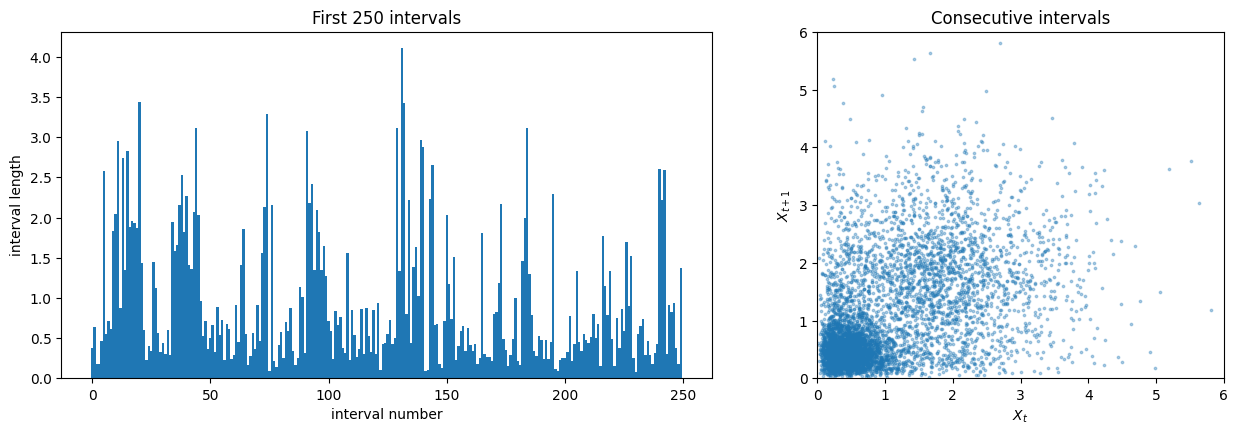

In [3]:
D0_true, D1_true, trace = pkl.load(open('../../pkls/map_fitting_example.pkl', 'rb'))
print('number of intervals:', len(trace))
print('mean = %.3f,  SCV = %.3f' % (trace.mean(), trace.var() / trace.mean()**2))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[1.6, 1]))
axs[0].bar(np.arange(250), trace[:250], width=1.0)
axs[0].set_title('First 250 intervals')
axs[0].set_xlabel('interval number'); axs[0].set_ylabel('interval length')
axs[1].scatter(trace[:-1][:6000], trace[1:][:6000], s=3, alpha=0.35)
axs[1].set_xlim(0, 6); axs[1].set_ylim(0, 6)
axs[1].set_xlabel('$X_t$'); axs[1].set_ylabel('$X_{t+1}$'); axs[1].set_title('Consecutive intervals')
plt.show()

<div dir="rtl">

### רואים בבירור רצפים של זמנים קצרים ורצפים של זמנים ארוכים.

### בגרף הימני: כשזמן אחד קצר — גם הבא בדרך כלל קצר (הענן הצפוף ליד הראשית).

### נחשב את שמונת מקדמי האוטו-קורלציה — מהנתונים, ומהתהליך האמיתי:

</div>

In [4]:
corr_table = pd.DataFrame({'true process': corr_from_map(D0_true, D1_true),
                           'data (50,000)': corr_from_trace(trace)}, index=COLS).T
corr_table.round(3)

,"lag1 (1,1)","lag1 (1,2)","lag1 (2,1)","lag1 (2,2)","lag2 (1,1)","lag2 (1,2)","lag2 (2,1)","lag2 (2,2)"
true process,0.450,0.373,0.373,0.308,0.315,0.261,0.261,0.216
"data (50,000)",0.456,0.382,0.380,0.318,0.313,0.262,0.259,0.218


<div dir="rtl">

### כל המקדמים חיוביים וגדולים: יש תלות חזקה, גם בפיגור 1 וגם בפיגור 2, וגם בחזקה השנייה.

### האומדנים מהנתונים קרובים מאוד לערכים האמיתיים — 50,000 תצפיות מספיקות כדי לאמוד אותם היטב.

</div>

<div dir="rtl">

## גישה 1: התאמת PH — מתעלמים מהתלות

### נתאים התפלגות פאזה עם 8 שלבים, בדיוק כמו בשיעור הקודם (`PHFromTrace`).

### ההתאמה רואה רק את ההיסטוגרמה. היא מניחה שכל הזמנים בלתי תלויים, ולכן כל מקדמי האוטו-קורלציה שלה הם אפס.

</div>

In [5]:
t0 = time.time()
a_ph, A_ph, ll_ph = PHFromTrace(trace, 8)
print('runtime: %.1f s' % (time.time() - t0))

a_ph = np.array(a_ph).ravel(); A_ph = np.array(A_ph)
# a PH renewal process written as a MAP: after every arrival, restart according to alpha
D0_ph, D1_ph = A_ph, np.outer(-A_ph @ np.ones(8), a_ph)
map_summary(D0_ph, D1_ph)

runtime: 5.3 s


{'mean': 0.9956516385388936, 'SCV': 0.8419724357370196}

<div dir="rtl">

## גישה 2: התאמת MAP

### `MAPFromTrace` הוא אלגוריתם EM שמתאים MAP מסוג מיוחד (ER-CHMM):

### - יש כמה **ענפים**, וכל ענף הוא התפלגות ארלנג.
### - כל זמן בין הגעות מוגרל מאחד הענפים.
### - הענף של הזמן הבא נבחר לפי מטריצת מעברים, שתלויה **בענף של הזמן הנוכחי** — כך נוצרת התלות.

### הפרמטר `orders` קובע כמה ענפים יש וכמה שלבים בכל ענף. למשל `[2, 2]` — שני ענפים עם שני שלבים בכל אחד, סך הכול 4 שלבים.

### נתאים MAP עם 2, 4, 6 ו-8 שלבים, ונשווה גם את הצורה וגם את התלות.

</div>

In [6]:
maps = {}
for orders in ([1, 1], [2, 2], [3, 3], [4, 4]):
    t0 = time.time()
    D0_fit, D1_fit, ll = MAPFromTrace(trace, orders)
    name = 'MAP-%d' % sum(orders)
    maps[name] = (np.array(D0_fit), np.array(D1_fit))
    print('%s  orders=%s  runtime=%.1f s  log-likelihood per sample=%.4f' % (name, orders, time.time() - t0, ll))

MAP-2  orders=[1, 1]  runtime=22.4 s  log-likelihood per sample=-0.9956


MAP-4  orders=[2, 2]  runtime=10.3 s  log-likelihood per sample=-0.7893


MAP-6  orders=[3, 3]  runtime=8.4 s  log-likelihood per sample=-0.7443


MAP-8  orders=[4, 4]  runtime=8.4 s  log-likelihood per sample=-0.7449


<div dir="rtl">

## השוואה 1: ההתפלגות השולית (הצורה)

### לכל מודל נחשב את ההתפלגות השולית (`MarginalDistributionFromMAP`) ונשווה להיסטוגרמה.

</div>

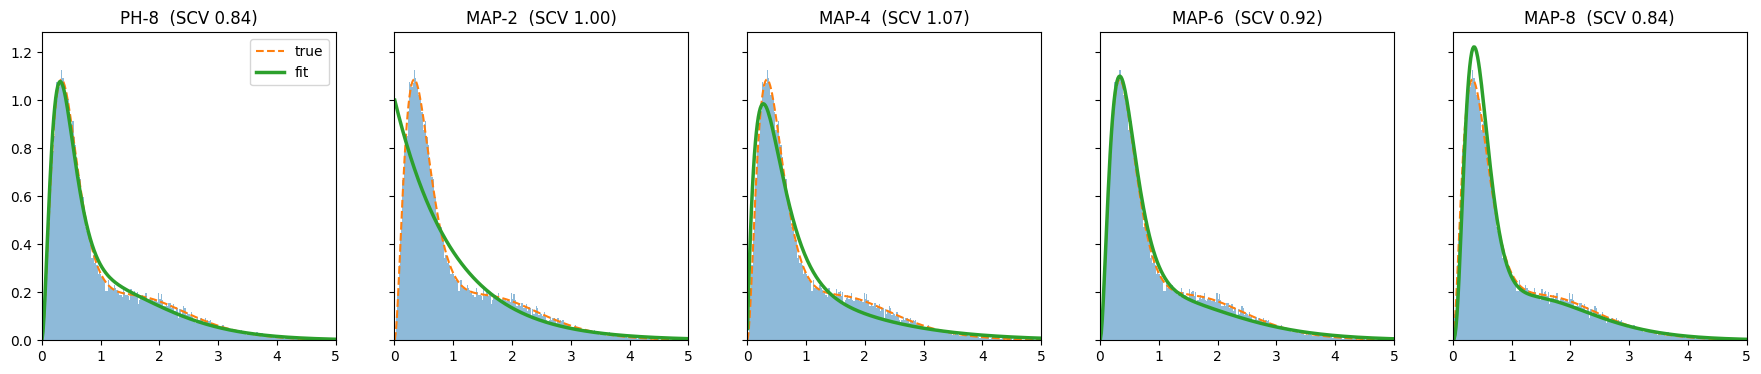

true SCV: 0.778


In [7]:
x = np.linspace(0.005, 5, 300)
a_t, A_t = MarginalDistributionFromMAP(np.matrix(D0_true), np.matrix(D1_true))
models = {'PH-8': (D0_ph, D1_ph), **maps}

fig, axs = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, (name, (M0, M1)) in zip(axs, models.items()):
    a_f, A_f = MarginalDistributionFromMAP(np.matrix(M0), np.matrix(M1))
    ax.hist(trace, bins=300, density=True, alpha=0.5)
    ax.plot(x, ph_pdf(a_t, A_t, x), '--', lw=1.5, label='true')
    ax.plot(x, ph_pdf(a_f, A_f, x), lw=2.5, label='fit')
    ax.set_xlim(0, 5); ax.set_title('%s  (SCV %.2f)' % (name, map_summary(M0, M1)['SCV']))
axs[0].legend()
plt.show()
print('true SCV: %.3f' % map_summary(D0_true, D1_true)['SCV'])

<div dir="rtl">

### התאמת ה-PH נראית מצוין — היא בנויה בדיוק בשביל זה.

### MAP עם 2 שלבים קטן מדי: הוא יצא מעריכי. עם 8 שלבים ההתפלגות השולית כבר קרובה מאוד לאמיתית.

</div>

<div dir="rtl">

## השוואה 2: התלות (מקדמי האוטו-קורלציה)

</div>

In [8]:
rows = {'true process': corr_from_map(D0_true, D1_true), 'data (50,000)': corr_from_trace(trace)}
for name, (M0, M1) in models.items():
    rows[name] = corr_from_map(M0, M1)
corr_all = pd.DataFrame(rows, index=COLS).T
corr_all.round(3)

,"lag1 (1,1)","lag1 (1,2)","lag1 (2,1)","lag1 (2,2)","lag2 (1,1)","lag2 (1,2)","lag2 (2,1)","lag2 (2,2)"
true process,0.450,0.373,0.373,0.308,0.315,0.261,0.261,0.216
"data (50,000)",0.456,0.382,0.380,0.318,0.313,0.262,0.259,0.218
PH-8,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000
MAP-2,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
MAP-4,0.276,0.196,0.196,0.139,0.215,0.153,0.153,0.109
MAP-6,0.351,0.261,0.261,0.194,0.257,0.191,0.191,0.142
MAP-8,0.392,0.302,0.302,0.233,0.273,0.211,0.211,0.162


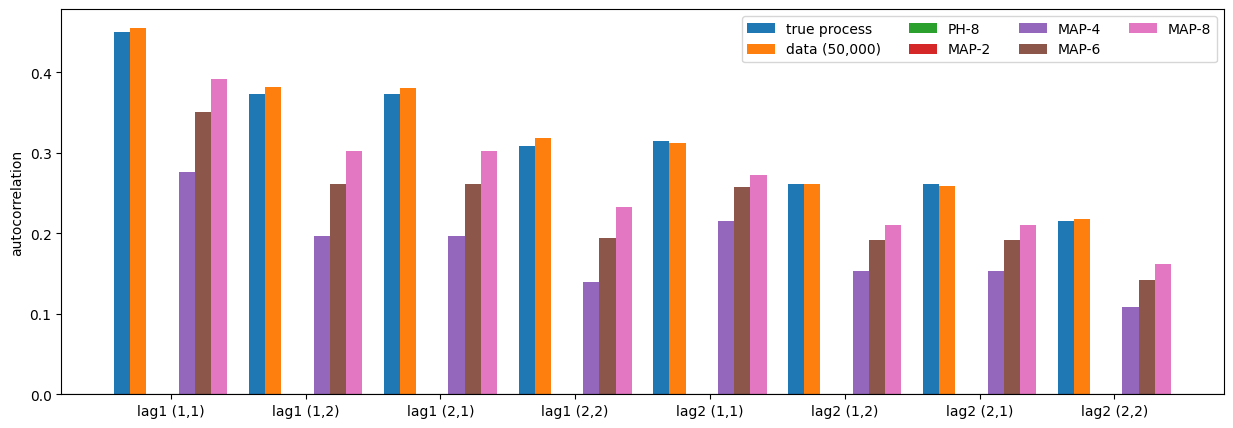

In [9]:
fig, ax = plt.subplots(figsize=(15, 5))
w = 0.12
for q, name in enumerate(corr_all.index):
    ax.bar(np.arange(8) + (q - 3) * w, corr_all.loc[name], w, label=name)
ax.set_xticks(np.arange(8)); ax.set_xticklabels(COLS)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('autocorrelation'); ax.legend(ncol=4)
plt.show()

<div dir="rtl">

### ההבדל הגדול:

### - **PH**: כל שמונת המקדמים הם אפס — הוא לא יכול לתאר תלות, לא משנה כמה שלבים ניתן לו.
### - **MAP עם 2 שלבים**: גם הוא יצא בלי תלות — מעט מדי שלבים.
### - **MAP עם 4 שלבים**: תופס כבר חלק מהתלות.
### - **MAP עם 8 שלבים**: קרוב לערכים האמיתיים בכל שמונת המקדמים — בפיגור 1 ובפיגור 2, ובחזקה הראשונה והשנייה.

### כלומר: ההתאמה הטובה של ה-PH להיסטוגרמה מסתירה את העובדה שהוא מפספס חצי מהתמונה.

</div>

<div dir="rtl">

## האם זה משנה את התור?

### נשתמש בכל מודל כ**תהליך ההגעה** של תור עם שרת אחד. זמני השירות מעריכיים בקצב 1.25, כך שהעומס הוא 80%.

### ל-MAP/M/1 יש פתרון מדויק (`MAPMAP1` ב-butools): התפלגות מספר הלקוחות במערכת וזמן השהייה הממוצע.

</div>

In [10]:
mu = 1.25
S0, S1 = np.matrix([[-mu]]), np.matrix([[mu]])
K = 60
queue = {}
for name, (M0, M1) in {'true process': (D0_true, D1_true), **models}.items():
    st_mean, pmf = MAPMAP1(np.matrix(M0), np.matrix(M1), S0, S1, 'stMoms', 1, 'ncDistr', K)
    queue[name] = dict(Wq=float(np.ravel(st_mean)[0]) - 1 / mu, pmf=np.ravel(pmf))

pmf_true = queue['true process']['pmf']
summary = pd.DataFrame({name: {'SCV': map_summary(*(models.get(name, (D0_true, D1_true))))['SCV'],
                               'lag1 corr': (rows[name][0]),
                               'mean wait': q['Wq'],
                               'error': q['Wq'] / queue['true process']['Wq'] - 1,
                               'SAE': np.abs(q['pmf'] - pmf_true).sum()}
                        for name, q in queue.items()}).T
summary.round(3)

,SCV,lag1 corr,mean wait,error,SAE
true process,0.778,0.450,6.449,0.000,0.000
PH-8,0.842,-0.000,2.975,-0.539,0.389
MAP-2,1.000,0.000,3.271,-0.493,0.345
MAP-4,1.067,0.276,7.564,0.173,0.079
MAP-6,0.925,0.351,7.013,0.087,0.043
MAP-8,0.842,0.392,6.499,0.008,0.011


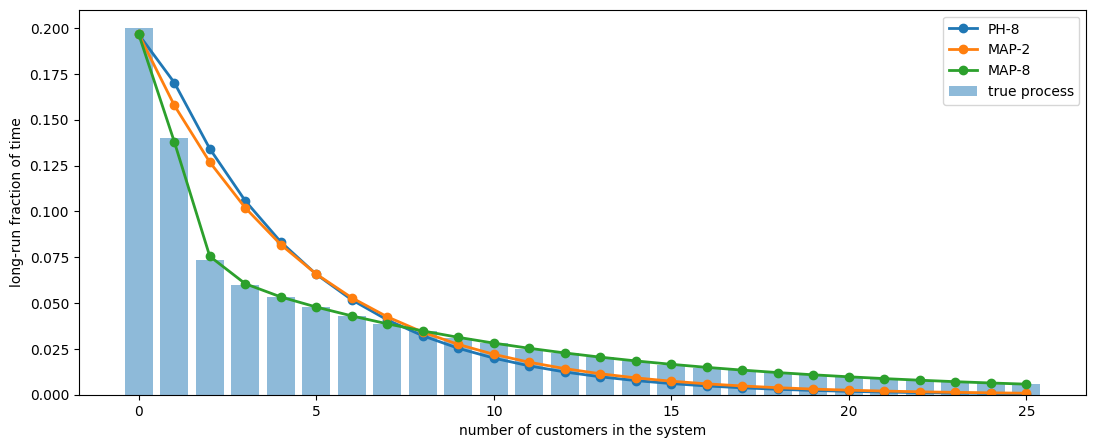

In [11]:
n = np.arange(26)
plt.figure(figsize=(13, 5))
plt.bar(n, pmf_true[:26], alpha=0.5, label='true process')
for name in ['PH-8', 'MAP-2', 'MAP-8']:
    plt.plot(n, queue[name]['pmf'][:26], marker='o', lw=2, label=name)
plt.xlabel('number of customers in the system'); plt.ylabel('long-run fraction of time')
plt.legend()
plt.show()

<div dir="rtl">

## בדיקה בסימולציה

### נוודא את התוצאות בסימולציה של 300,000 לקוחות, עם אותם זמני שירות לכל המודלים.

### כדי לדגום מ-MAP שהתאמנו, נשתמש במבנה שלו: ענפי ארלנג, ומטריצת מעברים בין הענפים.

</div>

In [12]:
rng = np.random.default_rng(11)


def erchmm_params(D0, D1, orders):
    """Erlang rates and branch transition matrix of an ER-CHMM given as (D0, D1)."""
    first = np.cumsum([0] + list(orders[:-1])); last = first + np.array(orders) - 1
    rates = -np.diag(D0)[first]
    P = np.array([[D1[last[i], first[j]] / rates[i] for j in range(len(orders))] for i in range(len(orders))])
    return rates, P


def sample_erchmm(orders, rates, P, n):
    C = np.cumsum(P, 1); u = rng.random(n); b = np.zeros(n, int)
    for i in range(1, n):
        b[i] = min(np.searchsorted(C[b[i - 1]], u[i], side='right'), len(orders) - 1)
    return rng.gamma(np.asarray(orders, float)[b], 1 / np.asarray(rates, float)[b])


def mean_wait(gaps, services):
    """Lindley recursion: W_{k+1} = max(0, W_k + S_k - A_k)."""
    w, total = 0.0, 0.0
    for k in range(len(services) - 1):
        w = max(0.0, w + services[k] - gaps[k])
        total += w
    return total / (len(services) - 1)


N = 300_000
services = rng.exponential(1 / mu, N)
arrivals = {'true process': sample_erchmm([3, 6], [6.0, 3.0], np.array([[0.9, 0.1], [0.2, 0.8]]), N),
            'PH-8': np.array(SamplesFromPH(np.matrix(a_ph), np.matrix(A_ph), N)).ravel(),
            'MAP-8': sample_erchmm([4, 4], *erchmm_params(*maps['MAP-8'], [4, 4]), N)}
for name, gaps in arrivals.items():
    print('%-13s simulated mean wait = %.2f   exact = %.2f' % (name, mean_wait(gaps, services), queue[name]['Wq']))

true process  simulated mean wait = 6.46   exact = 6.45
PH-8          simulated mean wait = 3.03   exact = 2.98
MAP-8         simulated mean wait = 6.63   exact = 6.50


<div dir="rtl">

## מה למדנו?

### **ה-PH טועה בחצי**: ההתפלגות השולית שלו כמעט מושלמת, אבל הוא מתעלם מהתלות — וזמן ההמתנה שהוא חוזה קטן בערך פי שניים מהאמיתי.

### **תלות חיובית מגדילה תורים**: כשזמנים קצרים מגיעים ברצף, לקוחות רבים מגיעים בזמן קצר והתור מתארך. מודל בלתי תלוי לא רואה את זה.

### **MAP עם מספיק שלבים**: תופס גם את הצורה וגם את התלות — ושגיאה של פחות מאחוז בזמן ההמתנה.

### **שמונה מספרים מתארים את התלות**: מקדמי האוטו-קורלציה בפיגורים 1 ו-2, בחזקות 1 ו-2. הם קלים לאמידה מהנתונים, ומאפשרים לבדוק אם המודל שהתאמנו תופס את התלות.

### **לפני שמתאימים התפלגות** — כדאי לבדוק אם יש תלות בנתונים. אם יש, PH לא יספיק.

</div>